⏳ Đang tải dữ liệu ETHUSDT khung 1h...
✅ Dữ liệu sẵn sàng. Tính toán Indicators...
🚀 Đang chạy Backtest MA40 + TEMA Trend Strategy...

METRICS (MA40 + TEMA Trend Following)
     Final Equity: 18683.7418
     Total Return: 0.8684
    CAGR (approx): 0.3032
     Max Drawdown: -0.1281
           Sharpe: 1.3469
           Trades: 582
          Winrate: 0.4038
    Avg PnL/Trade: 14.9205
    Profit Factor: 1.2195
           Max DD: -0.128146751649


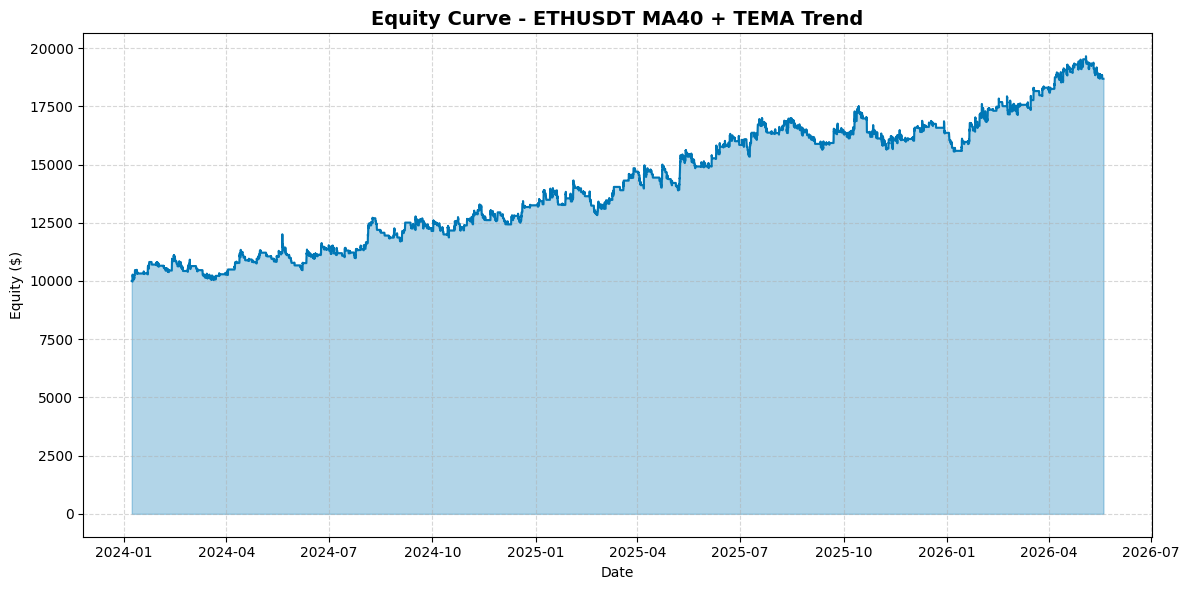


📊 Sample Trades (first 10):
            Exit Time   Type        Entry         Exit         PnL       Reason       Balance
0 2024-01-08 19:00:00   LONG  2271.450834  2354.339012  271.209145  Take Profit  10271.209145
1 2024-01-09 00:00:00   LONG  2336.390000  2299.735863 -102.712091    Stop Loss  10168.497053
2 2024-01-09 21:00:00  SHORT  2262.363272  2298.653473 -101.684971    Stop Loss  10066.812083
3 2024-01-10 09:00:00   LONG  2340.910000  2425.620000  184.101216    Time Exit  10250.913298
4 2024-01-11 07:00:00   LONG  2490.607363  2589.150000  167.999463    Time Exit  10418.912761
5 2024-01-12 16:00:00   LONG  2674.222282  2621.043488 -104.189128    Stop Loss  10314.723633
6 2024-01-13 07:00:00  SHORT  2556.325244  2550.990000    8.122110    Time Exit  10322.845744
7 2024-01-19 04:00:00  SHORT  2463.686390  2461.900000    6.454825    Time Exit  10329.300569
8 2024-01-22 10:00:00  SHORT  2422.426069  2368.274084  310.843482  Take Profit  10640.144052
9 2024-01-23 04:00:00  SHORT  2

In [1]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# --- 1. HÀM TẢI DỮ LIỆU ---
def str_to_millis(date_str):
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol, interval, start_str, end_str):
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    general_url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")
    
    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            response = requests.get(general_url, params=params, timeout=10)
            if response.status_code != 200:
                print("Error:", response.status_code, response.text)
                break
            data = response.json()
            if not data: break
            all_klines.extend(data)
            last_ts = data[-1][0]
            start_time = last_ts + 1
            time.sleep(0.05) 
        except Exception as e:
            print(f"Lỗi: {e}")
            break

    if not all_klines: return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df

# --- 2. HÀM TÍNH CHỈ BÁO ---
def calculate_indicators(df):
    data = df.copy()
    
    # True Range
    data['prev_close'] = data['Close'].shift(1)
    data['h_l'] = data['High'] - data['Low']
    data['h_pc'] = (data['High'] - data['prev_close']).abs()
    data['l_pc'] = (data['Low'] - data['prev_close']).abs()
    data['TR'] = data[['h_l', 'h_pc', 'l_pc']].max(axis=1)
    
    # ATR function
    def calc_atr(series_tr, period):
        return series_tr.ewm(alpha=1/period, min_periods=period, adjust=False).mean()
    
    # ATR các period
    data['ATR_20'] = calc_atr(data['TR'], 20)
    data['ATR_30'] = calc_atr(data['TR'], 30)
    data['ATR_179'] = calc_atr(data['TR'], 179)
    
    # MA(40) on Close
    data['MA_40'] = data['Close'].rolling(window=40).mean()
    
    # TEMA (Triple Exponential Moving Average)
    def calc_tema(series, period):
        ema1 = series.ewm(span=period, adjust=False).mean()
        ema2 = ema1.ewm(span=period, adjust=False).mean()
        ema3 = ema2.ewm(span=period, adjust=False).mean()
        tema = 3 * ema1 - 3 * ema2 + ema3
        return tema
    
    # TEMA(30) on HIGH and LOW
    data['TEMA_30_High'] = calc_tema(data['High'], 30)
    data['TEMA_30_Low'] = calc_tema(data['Low'], 30)
    
    data.dropna(inplace=True)
    return data

# --- 3. BACKTESTER ---
class MATEMATrendBacktester:
    def __init__(self, df, initial_balance=10000):
        self.df = df
        self.initial_balance = initial_balance
        self.balance = initial_balance
        self.equity_curve = [] 
        self.trades = []
        self.position = None 
        self.entry_price = 0
        self.sl = 0
        self.tp = 0
        self.entry_bar_idx = 0
        self.qty = 0
        self.pending_order = None 
        
        # Strategy Parameters
        self.risk_pct = 0.01  # 1%
        self.price_entry_mult = 2.0  # Entry buffer
        self.sl_coef = 1.7  # SL = 1.7 * ATR(20)
        self.tp_coef = 4.8  # TP = 4.8 * ATR(30)
        self.exit_after_bars = 10
        self.pending_expiration = 3
        
    def run(self):
        indices = self.df.index
        
        for i in range(len(self.df)):
            current_bar = self.df.iloc[i]
            idx = indices[i]
            
            # A. QUẢN LÝ LỆNH ĐANG MỞ
            if self.position is not None:
                # Check Exit After Bars
                bars_held = i - self.entry_bar_idx
                if bars_held >= self.exit_after_bars:
                    self.close_position(current_bar['Close'], idx, "Time Exit")
                    self.append_equity(idx)
                    continue
                
                # Check SL/TP
                if self.position == 'LONG':
                    # Check SL
                    if current_bar['Low'] <= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    
                    # Check TP
                    if current_bar['High'] >= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue
                
                elif self.position == 'SHORT':
                    # Check SL
                    if current_bar['High'] >= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    
                    # Check TP
                    if current_bar['Low'] <= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue
            
            # B. QUẢN LÝ PENDING ORDER
            if self.position is None and self.pending_order is not None:
                # Check expiration
                if i >= self.pending_order['expire_idx']:
                    self.pending_order = None
                else:
                    p_price = self.pending_order['price']
                    
                    if self.pending_order['type'] == 'BUY_STOP' and current_bar['High'] >= p_price:
                        self.open_position('LONG', max(p_price, current_bar['Open']), i, 
                                         self.pending_order['sl_dist'], 
                                         self.pending_order['tp_dist'])
                        self.pending_order = None
                    
                    elif self.pending_order['type'] == 'SELL_STOP' and current_bar['Low'] <= p_price:
                        self.open_position('SHORT', min(p_price, current_bar['Open']), i, 
                                         self.pending_order['sl_dist'], 
                                         self.pending_order['tp_dist'])
                        self.pending_order = None
            
            # C. TÍN HIỆU VÀO LỆNH
            if self.position is None and self.pending_order is None:
                # Cần ít nhất shift=2 để lấy ATR(179, shift=2)
                if i < 2:
                    self.append_equity(idx)
                    continue
                
                # Trend Filter (shift=1)
                close_shift1 = self.df.iloc[i-1]['Close']
                ma_40_shift1 = self.df.iloc[i-1]['MA_40']
                
                # Long Signal: Close > MA40
                long_signal = close_shift1 > ma_40_shift1
                
                # Short Signal: Close < MA40
                short_signal = close_shift1 < ma_40_shift1
                
                if not long_signal and not short_signal:
                    self.append_equity(idx)
                    continue
                
                # Entry parameters
                # TEMA(30) shift=1
                tema_high_shift1 = self.df.iloc[i-1]['TEMA_30_High']
                tema_low_shift1 = self.df.iloc[i-1]['TEMA_30_Low']
                
                # ATR(179) shift=2, rounded
                atr_179_shift2 = self.df.iloc[i-2]['ATR_179']
                atr_179_rounded = round(atr_179_shift2)
                
                # SL/TP parameters (shift=1)
                atr_20_shift1 = self.df.iloc[i-1]['ATR_20']
                atr_30_shift1 = self.df.iloc[i-1]['ATR_30']
                
                # CREATE PENDING ORDERS
                if long_signal:
                    entry_price = tema_high_shift1 + (self.price_entry_mult * atr_179_rounded)
                    sl_distance = self.sl_coef * atr_20_shift1
                    tp_distance = self.tp_coef * atr_30_shift1
                    
                    self.pending_order = {
                        'type': 'BUY_STOP',
                        'price': entry_price,
                        'sl_dist': sl_distance,
                        'tp_dist': tp_distance,
                        'expire_idx': i + self.pending_expiration
                    }
                
                elif short_signal and not long_signal:
                    entry_price = tema_low_shift1 - (self.price_entry_mult * atr_179_rounded)
                    sl_distance = self.sl_coef * atr_20_shift1
                    tp_distance = self.tp_coef * atr_30_shift1
                    
                    self.pending_order = {
                        'type': 'SELL_STOP',
                        'price': entry_price,
                        'sl_dist': sl_distance,
                        'tp_dist': tp_distance,
                        'expire_idx': i + self.pending_expiration
                    }
            
            # D. APPEND EQUITY
            self.append_equity(idx)
    
    def append_equity(self, idx):
        """Tính equity bao gồm unrealized P&L"""
        mark_to_market = self.balance
        if self.position == 'LONG':
            current_price = self.df.loc[idx, 'Close']
            unrealized = (current_price - self.entry_price) * self.qty
            mark_to_market += unrealized
        elif self.position == 'SHORT':
            current_price = self.df.loc[idx, 'Close']
            unrealized = (self.entry_price - current_price) * self.qty
            mark_to_market += unrealized
        
        self.equity_curve.append({'time': idx, 'equity': mark_to_market})
    
    def open_position(self, pos_type, price, bar_idx, sl_dist, tp_dist):
        self.position = pos_type
        self.entry_price = price
        self.entry_bar_idx = bar_idx
        
        # Set SL/TP
        if pos_type == 'LONG':
            self.sl = price - sl_dist
            self.tp = price + tp_dist
        else:
            self.sl = price + sl_dist
            self.tp = price - tp_dist
        
        # Calculate position size (Risk Fixed %)
        risk_amount = self.balance * self.risk_pct
        sl_distance = abs(price - self.sl)
        self.qty = risk_amount / sl_distance if sl_distance > 0 else 0
    
    def close_position(self, price, time_idx, reason):
        if self.position == 'LONG':
            pnl = (price - self.entry_price) * self.qty
        else:
            pnl = (self.entry_price - price) * self.qty
        
        self.balance += pnl
        
        self.trades.append({
            'Exit Time': time_idx,
            'Type': self.position,
            'Entry': self.entry_price,
            'Exit': price,
            'PnL': pnl,
            'Reason': reason,
            'Balance': self.balance
        })
        
        # Reset position
        self.position = None
        self.qty = 0

# --- 4. HÀM TÍNH METRICS ---
def calculate_advanced_metrics(trades_df, equity_data, initial_balance):
    eq_df = pd.DataFrame(equity_data)
    eq_df.set_index('time', inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep='last')]
    
    final_equity = eq_df['equity'].iloc[-1]
    total_return = (final_equity - initial_balance) / initial_balance
    
    # CAGR
    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25
    cagr = ((final_equity / initial_balance) ** (1/years)) - 1 if years > 0 else 0
    
    # Max Drawdown
    running_max = eq_df['equity'].cummax()
    drawdown = (eq_df['equity'] - running_max) / running_max
    max_dd = drawdown.min()
    
    # Sharpe Ratio
    eq_df['returns'] = eq_df['equity'].pct_change()
    mean_ret = eq_df['returns'].mean()
    std_ret = eq_df['returns'].std()
    bars_per_year = len(eq_df) / years if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret != 0 else 0
    
    # Trade Metrics
    total_trades = len(trades_df)
    win_trades = len(trades_df[trades_df['PnL'] > 0])
    win_rate = win_trades / total_trades if total_trades > 0 else 0
    avg_pnl = trades_df['PnL'].mean() if total_trades > 0 else 0
    
    # Profit Factor
    gross_profit = trades_df[trades_df['PnL'] > 0]['PnL'].sum()
    gross_loss = abs(trades_df[trades_df['PnL'] < 0]['PnL'].sum())
    profit_factor = gross_profit / gross_loss if gross_loss > 0 else 0

    return {
        'Final Equity': final_equity,
        'Total Return': total_return,
        'CAGR (approx)': cagr,
        'Max Drawdown': max_dd,
        'Sharpe': sharpe,
        'Trades': total_trades,
        'Winrate': win_rate,
        'Avg PnL/Trade': avg_pnl,
        'Profit Factor': profit_factor,
        'equity_df': eq_df
    }

def print_report_and_plot(metrics, symbol):
    print("\n" + "="*60)
    print("METRICS (MA40 + TEMA Trend Following)")
    print("="*60)
    print(f"     Final Equity: {metrics['Final Equity']:.4f}")
    print(f"     Total Return: {metrics['Total Return']:.4f}")
    print(f"    CAGR (approx): {metrics['CAGR (approx)']:.4f}")
    print(f"     Max Drawdown: {metrics['Max Drawdown']:.4f}")
    print(f"           Sharpe: {metrics['Sharpe']:.4f}")
    print(f"           Trades: {metrics['Trades']}")
    print(f"          Winrate: {metrics['Winrate']:.4f}")
    print(f"    Avg PnL/Trade: {metrics['Avg PnL/Trade']:.4f}")
    print(f"    Profit Factor: {metrics['Profit Factor']:.4f}")
    print(f"           Max DD: {metrics['Max Drawdown']:.12f}")
    print("="*60)

    eq_df = metrics['equity_df']
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df['equity'], linewidth=1.5, color='#0077B6')
    plt.fill_between(eq_df.index, eq_df['equity'], alpha=0.3, color='#0077B6')
    
    plt.title(f"Equity Curve - {symbol} MA40 + TEMA Trend", fontsize=14, fontweight='bold')
    plt.xlabel('Date')
    plt.ylabel('Equity ($)')
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

# --- 5. MAIN EXECUTION ---
if __name__ == "__main__":
    symbol = "ETHUSDT"
    interval = "1h"
    start_date = "01/01/2024"
    end_date = "19/05/2026"

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)

    if len(df_raw) > 200:
        print("✅ Dữ liệu sẵn sàng. Tính toán Indicators...")
        df_calc = calculate_indicators(df_raw)
        
        print("🚀 Đang chạy Backtest MA40 + TEMA Trend Strategy...")
        bt = MATEMATrendBacktester(df_calc, initial_balance=10000)
        bt.run()
        
        trades_df = pd.DataFrame(bt.trades)
        
        if not trades_df.empty:
            metrics = calculate_advanced_metrics(trades_df, bt.equity_curve, bt.initial_balance)
            print_report_and_plot(metrics, symbol)
            
            print("\n📊 Sample Trades (first 10):")
            print(trades_df.head(10).to_string())
            
            print("\n📊 Exit Reasons Distribution:")
            print(trades_df['Reason'].value_counts())
            
            print("\n📊 Long vs Short Distribution:")
            print(trades_df['Type'].value_counts())
        else:
            print("⚠️ Không có lệnh nào được thực hiện.")
    else:
        print("❌ Không đủ dữ liệu.")

⏳ Đang tải dữ liệu ETHUSDT khung 2h...
✅ Dữ liệu sẵn sàng. Tính indicators...
🚀 Đang chạy backtest MA40 + TEMA (enhanced trend filter)...

🎯 METRICS (MA40 slope + ATR distance + TEMA breakout + Fees)
     Final Equity: 14941.2687
     Total Return: 0.4941
    CAGR (approx): 0.1871
     Max Drawdown: -0.0947
           Sharpe: 1.2792
           Trades: 233
          Winrate: 0.4249
    Avg PnL/Trade: 21.2072
    Profit Factor: 1.3162


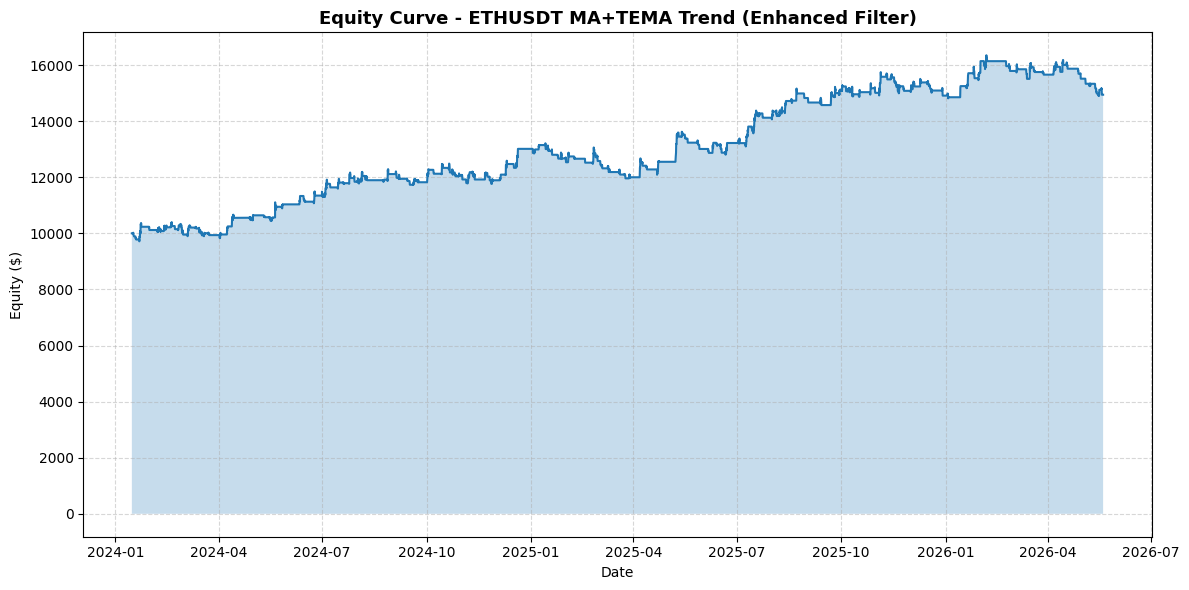


📊 Sample Trades (first 10):
            Exit Time   Type        Entry         Exit       Qty   PnL_gross  EntryFee   ExitFee   TotalFee     PnL_net       Reason       Balance
0 2024-01-17 08:00:00   LONG  2594.378695  2544.958731  2.023474 -100.000000  5.249657  5.149657  10.399314 -110.399314    Stop Loss   9889.600686
1 2024-01-19 08:00:00  SHORT  2439.500000  2481.579730  2.350205  -98.896007  5.733326  5.832222  11.565548 -110.461555    Stop Loss   9779.139131
2 2024-01-22 18:00:00  SHORT  2412.230697  2325.410278  3.686330  320.048682  8.892277  8.572229  17.464506  302.584176  Take Profit  10081.723307
3 2024-01-23 12:00:00  SHORT  2312.695108  2200.989170  2.468575  275.754482  5.709061  5.433307  11.142368  264.612114  Take Profit  10346.335420
4 2024-01-23 22:00:00  SHORT  2194.730454  2244.035584  2.098430 -103.463354  4.605488  4.708951   9.314439 -112.777793    Stop Loss  10233.557627
5 2024-01-30 22:00:00   LONG  2380.652588  2343.850708  2.780716 -102.335576  6.619919  6

In [4]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# =========================================================
# 1) FETCH BINANCE DATA
# =========================================================
def str_to_millis(date_str: str) -> int:
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol: str, interval: str, start_str: str, end_str: str) -> pd.DataFrame:
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")

    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            response = requests.get(url, params=params, timeout=10)
            if response.status_code != 200:
                print("Error:", response.status_code, response.text)
                break

            data = response.json()
            if not data:
                break

            all_klines.extend(data)
            start_time = data[-1][0] + 1
            time.sleep(0.05)

        except Exception as e:
            print(f"Lỗi tải dữ liệu: {e}")
            break

    if not all_klines:
        return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df


# =========================================================
# 2) INDICATORS
# =========================================================
def calculate_indicators(df: pd.DataFrame) -> pd.DataFrame:
    data = df.copy()

    # True Range
    prev_close = data["Close"].shift(1)
    tr = pd.concat([
        (data["High"] - data["Low"]),
        (data["High"] - prev_close).abs(),
        (data["Low"] - prev_close).abs(),
    ], axis=1).max(axis=1)
    data["TR"] = tr

    # ATR Wilder
    def calc_atr(tr_series: pd.Series, period: int) -> pd.Series:
        return tr_series.ewm(alpha=1/period, min_periods=period, adjust=False).mean()

    data["ATR_20"] = calc_atr(data["TR"], 20)
    data["ATR_30"] = calc_atr(data["TR"], 30)
    data["ATR_179"] = calc_atr(data["TR"], 179)

    # MA40
    data["MA_40"] = data["Close"].rolling(window=40).mean()

    # TEMA
    def calc_tema(series: pd.Series, period: int) -> pd.Series:
        ema1 = series.ewm(span=period, adjust=False).mean()
        ema2 = ema1.ewm(span=period, adjust=False).mean()
        ema3 = ema2.ewm(span=period, adjust=False).mean()
        return 3 * ema1 - 3 * ema2 + ema3

    data["TEMA_30_High"] = calc_tema(data["High"], 30)
    data["TEMA_30_Low"] = calc_tema(data["Low"], 30)

    data.dropna(inplace=True)
    return data


# =========================================================
# 3) BACKTESTER (MA + TEMA Trend + ATR Distance Filter + Fees)
# =========================================================
class MATEMATrendBacktester:
    def __init__(self, df: pd.DataFrame, initial_balance: float = 10000.0):
        self.df = df
        self.initial_balance = float(initial_balance)
        self.balance = float(initial_balance)

        self.equity_curve = []
        self.trades = []

        # Position state
        self.position = None  # "LONG" / "SHORT" / None
        self.entry_price = 0.0
        self.sl = 0.0
        self.tp = 0.0
        self.entry_bar_idx = 0
        self.qty = 0.0

        # Pending
        self.pending_order = None

        # Params
        self.risk_pct = 0.01
        self.price_entry_mult = 2.0     # buffer * ATR179(round)
        self.sl_coef = 1.7              # SL = 1.7 * ATR20
        self.tp_coef = 4.8              # TP = 4.8 * ATR30
        self.exit_after_bars = 10
        self.pending_expiration = 3

        # Trend filter upgrade params
        self.ma_slope_lookback = 4      # compare MA40[i-1] vs MA40[i-4]
        self.dist_atr_threshold = 0.40  # normalized distance threshold

        # Fees (taker style)
        self.fee_rate = 0.001           # 0.1%/side (spot default)
        self._last_entry_fee = 0.0

    def run(self):
        idxs = self.df.index

        for i in range(len(self.df)):
            bar = self.df.iloc[i]
            t = idxs[i]

            # -----------------------------
            # A) Manage open position
            # -----------------------------
            if self.position is not None:
                held = i - self.entry_bar_idx

                # Time exit
                if held >= self.exit_after_bars:
                    self.close_position(float(bar["Close"]), t, "Time Exit")
                    self.append_equity(t)
                    continue

                if self.position == "LONG":
                    # Conservative: SL checked before TP in same bar
                    if bar["Low"] <= self.sl:
                        self.close_position(float(self.sl), t, "Stop Loss")
                        self.append_equity(t)
                        continue
                    if bar["High"] >= self.tp:
                        self.close_position(float(self.tp), t, "Take Profit")
                        self.append_equity(t)
                        continue

                elif self.position == "SHORT":
                    if bar["High"] >= self.sl:
                        self.close_position(float(self.sl), t, "Stop Loss")
                        self.append_equity(t)
                        continue
                    if bar["Low"] <= self.tp:
                        self.close_position(float(self.tp), t, "Take Profit")
                        self.append_equity(t)
                        continue

            # -----------------------------
            # B) Manage pending order
            # -----------------------------
            if self.position is None and self.pending_order is not None:
                if i >= self.pending_order["expire_idx"]:
                    self.pending_order = None
                else:
                    p = self.pending_order["price"]

                    if self.pending_order["type"] == "BUY_STOP":
                        if bar["High"] >= p:
                            fill = max(float(p), float(bar["Open"]))  # gap-aware stop fill
                            self.open_position(
                                "LONG", fill, i,
                                self.pending_order["sl_dist"],
                                self.pending_order["tp_dist"]
                            )
                            self.pending_order = None

                    elif self.pending_order["type"] == "SELL_STOP":
                        if bar["Low"] <= p:
                            fill = min(float(p), float(bar["Open"]))
                            self.open_position(
                                "SHORT", fill, i,
                                self.pending_order["sl_dist"],
                                self.pending_order["tp_dist"]
                            )
                            self.pending_order = None

            # -----------------------------
            # C) Signal -> place pending
            # -----------------------------
            if self.position is None and self.pending_order is None:
                # Need enough bars for slope lookback and shifts
                min_need = max(2, self.ma_slope_lookback)
                if i < min_need:
                    self.append_equity(t)
                    continue

                # Trend filter (shift=1)
                close_1 = float(self.df.iloc[i-1]["Close"])
                ma40_1 = float(self.df.iloc[i-1]["MA_40"])
                atr20_1 = float(self.df.iloc[i-1]["ATR_20"])

                # MA slope compare: MA40[i-1] vs MA40[i-lookback]
                ma_ref_idx = i - self.ma_slope_lookback
                ma40_ref = float(self.df.iloc[ma_ref_idx]["MA_40"])

                if atr20_1 <= 0:
                    self.append_equity(t)
                    continue

                dist_norm = (close_1 - ma40_1) / atr20_1
                ma_slope_up = ma40_1 > ma40_ref
                ma_slope_down = ma40_1 < ma40_ref

                long_signal = (close_1 > ma40_1) and ma_slope_up and (dist_norm > self.dist_atr_threshold)
                short_signal = (close_1 < ma40_1) and ma_slope_down and (dist_norm < -self.dist_atr_threshold)

                if not long_signal and not short_signal:
                    self.append_equity(t)
                    continue

                # Entry params
                tema_high_1 = float(self.df.iloc[i-1]["TEMA_30_High"])
                tema_low_1 = float(self.df.iloc[i-1]["TEMA_30_Low"])

                atr179_2 = float(self.df.iloc[i-2]["ATR_179"])
                atr179_round = round(atr179_2)

                # SL/TP distances from shift=1
                atr30_1 = float(self.df.iloc[i-1]["ATR_30"])
                sl_dist = self.sl_coef * atr20_1
                tp_dist = self.tp_coef * atr30_1

                # Guard
                if sl_dist <= 0 or tp_dist <= 0:
                    self.append_equity(t)
                    continue

                if long_signal:
                    entry = tema_high_1 + self.price_entry_mult * atr179_round
                    self.pending_order = {
                        "type": "BUY_STOP",
                        "price": float(entry),
                        "sl_dist": float(sl_dist),
                        "tp_dist": float(tp_dist),
                        "expire_idx": i + self.pending_expiration
                    }

                elif short_signal:
                    entry = tema_low_1 - self.price_entry_mult * atr179_round
                    self.pending_order = {
                        "type": "SELL_STOP",
                        "price": float(entry),
                        "sl_dist": float(sl_dist),
                        "tp_dist": float(tp_dist),
                        "expire_idx": i + self.pending_expiration
                    }

            # -----------------------------
            # D) Append equity
            # -----------------------------
            self.append_equity(t)

    def append_equity(self, t):
        mtm = self.balance
        close_px = float(self.df.loc[t, "Close"])

        if self.position == "LONG":
            mtm += (close_px - self.entry_price) * self.qty
        elif self.position == "SHORT":
            mtm += (self.entry_price - close_px) * self.qty

        self.equity_curve.append({"time": t, "equity": mtm})

    def open_position(self, pos_type: str, price: float, bar_idx: int, sl_dist: float, tp_dist: float):
        self.position = pos_type
        self.entry_price = float(price)
        self.entry_bar_idx = int(bar_idx)

        if pos_type == "LONG":
            self.sl = self.entry_price - sl_dist
            self.tp = self.entry_price + tp_dist
        else:
            self.sl = self.entry_price + sl_dist
            self.tp = self.entry_price - tp_dist

        # Fixed-risk position sizing
        risk_amount = self.balance * self.risk_pct
        sl_distance = abs(self.entry_price - self.sl)
        self.qty = float(risk_amount / sl_distance) if sl_distance > 0 else 0.0

        # Entry fee (deduct immediately)
        entry_notional = self.entry_price * self.qty
        entry_fee = self.fee_rate * entry_notional
        self.balance -= entry_fee
        self._last_entry_fee = float(entry_fee)

    def close_position(self, price: float, t, reason: str):
        price = float(price)

        if self.position == "LONG":
            pnl_gross = (price - self.entry_price) * self.qty
        else:
            pnl_gross = (self.entry_price - price) * self.qty

        # Exit fee
        exit_notional = price * self.qty
        exit_fee = self.fee_rate * exit_notional

        # Entry fee already deducted at open
        pnl_net_added_to_balance = pnl_gross - exit_fee
        self.balance += pnl_net_added_to_balance

        self.trades.append({
            "Exit Time": t,
            "Type": self.position,
            "Entry": self.entry_price,
            "Exit": price,
            "Qty": self.qty,
            "PnL_gross": pnl_gross,
            "EntryFee": self._last_entry_fee,
            "ExitFee": exit_fee,
            "TotalFee": self._last_entry_fee + exit_fee,
            "PnL_net": pnl_gross - (self._last_entry_fee + exit_fee),
            "Reason": reason,
            "Balance": self.balance
        })

        # Reset
        self.position = None
        self.entry_price = 0.0
        self.sl = 0.0
        self.tp = 0.0
        self.qty = 0.0
        self._last_entry_fee = 0.0


# =========================================================
# 4) METRICS + PLOT
# =========================================================
def calculate_metrics(trades_df: pd.DataFrame, equity_data, initial_balance: float):
    eq_df = pd.DataFrame(equity_data)
    eq_df.set_index("time", inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep="last")]

    final_equity = float(eq_df["equity"].iloc[-1])
    total_return = (final_equity - initial_balance) / initial_balance

    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25 if days > 0 else 0.0
    cagr = ((final_equity / initial_balance) ** (1 / years) - 1) if years > 0 else 0.0

    running_max = eq_df["equity"].cummax()
    dd = (eq_df["equity"] - running_max) / running_max
    max_dd = float(dd.min())

    eq_df["returns"] = eq_df["equity"].pct_change()
    mean_ret = eq_df["returns"].mean()
    std_ret = eq_df["returns"].std()
    bars_per_year = (len(eq_df) / years) if years > 0 else 8760
    sharpe = float((mean_ret / std_ret) * np.sqrt(bars_per_year)) if (std_ret is not None and std_ret != 0) else 0.0

    pnl_col = "PnL_net" if "PnL_net" in trades_df.columns else "PnL"
    total_trades = len(trades_df)
    win_trades = len(trades_df[trades_df[pnl_col] > 0])
    win_rate = (win_trades / total_trades) if total_trades > 0 else 0.0
    avg_pnl = float(trades_df[pnl_col].mean()) if total_trades > 0 else 0.0

    gross_profit = float(trades_df[trades_df[pnl_col] > 0][pnl_col].sum()) if total_trades > 0 else 0.0
    gross_loss = abs(float(trades_df[trades_df[pnl_col] < 0][pnl_col].sum())) if total_trades > 0 else 0.0
    profit_factor = (gross_profit / gross_loss) if gross_loss > 0 else 0.0

    return {
        "Final Equity": final_equity,
        "Total Return": total_return,
        "CAGR (approx)": cagr,
        "Max Drawdown": max_dd,
        "Sharpe": sharpe,
        "Trades": total_trades,
        "Winrate": win_rate,
        "Avg PnL/Trade": avg_pnl,
        "Profit Factor": profit_factor,
        "equity_df": eq_df
    }

def print_report_and_plot(metrics, symbol: str):
    print("\n" + "=" * 70)
    print("🎯 METRICS (MA40 slope + ATR distance + TEMA breakout + Fees)")
    print("=" * 70)
    print(f"     Final Equity: {metrics['Final Equity']:.4f}")
    print(f"     Total Return: {metrics['Total Return']:.4f}")
    print(f"    CAGR (approx): {metrics['CAGR (approx)']:.4f}")
    print(f"     Max Drawdown: {metrics['Max Drawdown']:.4f}")
    print(f"           Sharpe: {metrics['Sharpe']:.4f}")
    print(f"           Trades: {metrics['Trades']}")
    print(f"          Winrate: {metrics['Winrate']:.4f}")
    print(f"    Avg PnL/Trade: {metrics['Avg PnL/Trade']:.4f}")
    print(f"    Profit Factor: {metrics['Profit Factor']:.4f}")
    print("=" * 70)

    eq_df = metrics["equity_df"]
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df["equity"], linewidth=1.5)
    plt.fill_between(eq_df.index, eq_df["equity"], alpha=0.25)
    plt.title(f"Equity Curve - {symbol} MA+TEMA Trend (Enhanced Filter)", fontsize=13, fontweight="bold")
    plt.xlabel("Date")
    plt.ylabel("Equity ($)")
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


# =========================================================
# 5) MAIN
# =========================================================
if __name__ == "__main__":
    symbol = "ETHUSDT"
    interval = "2h"
    start_date = "01/01/2024"
    end_date = "19/05/2026"

    initial_balance = 10000.0

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)

    if df_raw is None or df_raw.empty or len(df_raw) < 500:
        print("❌ Không đủ dữ liệu.")
    else:
        print("✅ Dữ liệu sẵn sàng. Tính indicators...")
        df_calc = calculate_indicators(df_raw)

        if df_calc.empty:
            print("❌ Không đủ dữ liệu sau khi tính indicators.")
        else:
            print("🚀 Đang chạy backtest MA40 + TEMA (enhanced trend filter)...")
            bt = MATEMATrendBacktester(df_calc, initial_balance=initial_balance)

            # Quick tune (tuỳ chỉnh nhanh)
            # bt.dist_atr_threshold = 0.5
            # bt.ma_slope_lookback = 5
            # bt.fee_rate = 0.0006  # VIP/BNB fee nếu muốn
            # bt.price_entry_mult = 1.8

            bt.run()
            trades_df = pd.DataFrame(bt.trades)

            if not trades_df.empty:
                metrics = calculate_metrics(trades_df, bt.equity_curve, bt.initial_balance)
                print_report_and_plot(metrics, symbol)

                print("\n📊 Sample Trades (first 10):")
                print(trades_df.head(10).to_string())

                print("\n📈 Exit Reasons:")
                print(trades_df["Reason"].value_counts())

                print("\n📈 Long vs Short:")
                print(trades_df["Type"].value_counts())
            else:
                print("⚠️ Không có lệnh nào được thực hiện.")